# Bearing Fault Diagnosis from Vibration Signals with a 1D CNN
**Author:** Min Khaung Min Lwin

**Dataset:** Case Western Reserve University (CWRU) Bearing Data Center — 12 kHz drive-end fault data and normal baseline data, https://engineering.case.edu/bearingdatacenter

**Task type:** Image/signal classification with a **Convolutional Neural Network (1D CNN)**: classify raw vibration windows into 4 classes (normal, inner-race fault, ball fault, outer-race fault).



--------

## 1. Data Loading and Inspection

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, torch
from scipy.io import loadmat
from pathlib import Path

DATA = Path("data/cwru")
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(torch.__version__, device)

2.15.0 mps


In [2]:
manifest = pd.read_csv(DATA / "manifest.csv")
rows = []
for _, r in manifest.iterrows():
    m = loadmat(DATA / r["file"])
    keys = [k for k in m if not k.startswith("__")]
    de = [k for k in keys if k.endswith("DE_time")]
    rpm = [float(m[k].squeeze()) for k in keys if "RPM" in k]
    rows.append({"file": r["file"], "label": r["label"], "size": r["fault_size"], "load": r["load_hp"],
                 "de_keys": de, "n_samples": [m[k].size for k in de], "rpm": rpm})
inspect = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", None)
inspect

,file,label,size,load,de_keys,n_samples,rpm
0,97.mat,normal,0.000,0,[X097_DE_time],[243938],[1796.0]
1,98.mat,normal,0.000,1,[X098_DE_time],[483903],[]
2,99.mat,normal,0.000,2,"[X098_DE_time, X099_DE_time]","[483903, 485063]",[]
3,100.mat,normal,0.000,3,[X100_DE_time],[485643],[1725.0]
4,105.mat,inner_race,0.007,0,[X105_DE_time],[121265],[1797.0]
5,106.mat,inner_race,0.007,1,[X106_DE_time],[121991],[1772.0]
6,107.mat,inner_race,0.007,2,[X107_DE_time],[122136],[1748.0]
7,108.mat,inner_race,0.007,3,[X108_DE_time],[122917],[1721.0]
8,169.mat,inner_race,0.014,0,[X169_DE_time],[121846],[1796.0]
9,170.mat,inner_race,0.014,1,[X170_DE_time],[121846],[1774.0]


#### Step 1: confirm the normal files’ sampling rate

Fault 105 @12 kHz: strongest peak between 5–60 Hz at 60 Hz
Normal 97 assumed 12 kHz: strongest peak between 5–60 Hz at 40 Hz
Normal 97 assumed 48 kHz: strongest peak between 5–60 Hz at 30 Hz


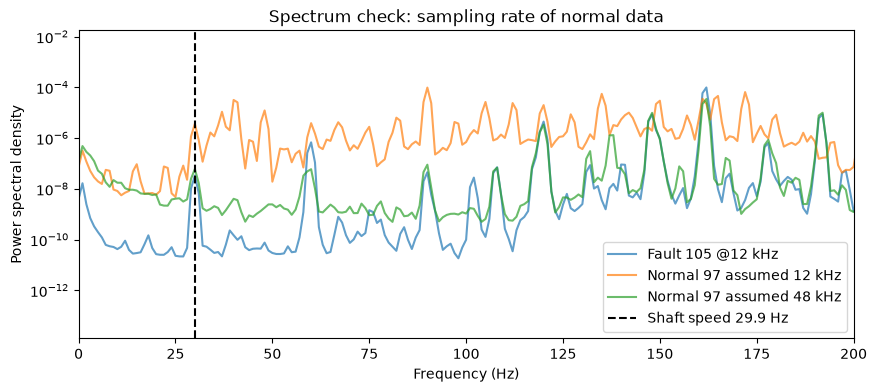

In [3]:
from scipy.signal import welch

def get_de(path):
    """Return the drive-end signal whose number matches the file name (handles files with extra keys)."""
    m = loadmat(path)
    key = f"X{int(Path(path).stem):03d}_DE_time"
    return m[key].squeeze()

x_normal = get_de(DATA / "97.mat")
x_fault = get_de(DATA / "105.mat")      # known 12 kHz, load 0

fig, ax = plt.subplots(figsize=(10, 4))
for x, fs, lab in [(x_fault, 12000, "Fault 105 @12 kHz"),
                   (x_normal, 12000, "Normal 97 assumed 12 kHz"),
                   (x_normal, 48000, "Normal 97 assumed 48 kHz")]:
    f, p = welch(x, fs=fs, nperseg=fs)          # 1 Hz resolution
    band = (f >= 5) & (f <= 60)
    print(f"{lab}: strongest peak between 5–60 Hz at {f[band][np.argmax(p[band])]:.0f} Hz")
    ax.semilogy(f, p, label=lab, alpha=0.7)
ax.axvline(1796 / 60, color="k", linestyle="--", label="Shaft speed 29.9 Hz")
ax.set_xlim(0, 200); ax.set_title("Spectrum check: sampling rate of normal data")
ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Power spectral density"); ax.legend()
plt.show()

#### Step 2 (after the check): load, window and split

In [ ]:
from scipy.signal import decimate

WIN = 2048            # ≈0.17 s at 12 kHz, about 5 shaft revolutions
CLASSES = ["normal", "inner_race", "ball", "outer_race"]

def load_signal(row, normal_fs=48000):
    """Load the matching DE signal; resample 48 kHz normal data to 12 kHz with an anti-aliasing filter."""
    x = get_de(DATA / row["file"])
    if row["label"] == "normal" and normal_fs == 48000:
        x = decimate(x, 4, zero_phase=True)
    return x.astype(np.float32)

def make_windows(x, stride):
    n = (len(x) - WIN) // stride + 1
    return np.stack([x[i * stride: i * stride + WIN] for i in range(n)])

def build_split(loads, stride):
    X, y = [], []
    for _, r in manifest[manifest["load_hp"].isin(loads)].iterrows():
        w = make_windows(load_signal(r), stride)
        X.append(w); y.append(np.full(len(w), CLASSES.index(r["label"])))
    return np.concatenate(X), np.concatenate(y)

# Train: loads 0–1 (overlapping windows for more samples); Val: load 2; Test: load 3 (non-overlapping)
X_train, y_train = build_split([0, 1], stride=512)
X_val, y_val = build_split([2], stride=WIN)
X_test, y_test = build_split([3], stride=WIN)

for name, (X, y) in {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}.items():
    print(name, X.shape, np.bincount(y, minlength=4))